# Control de calidad de limones con redes convolucionales
**Objetivo:** desarrollar un sistema de visión por computador que clasifique imágenes de limones en tres categorías (`bad_quality`, `good_quality` y `empty_background`). Comparamos una CNN propia con un modelo preentrenado (ResNet50 con transfer learning) y evaluamos aspectos técnicos, éticos y prácticos de su uso en una línea de inspección.
#### Juan Esteban Geiringer
#### Sergio Arbelaez
#### Nicol Violeta Gomez
#### Angelica Martinez
#### Sofia Suarez

## 1. Configuración y carga de datos
Cargamos el dataset con `ImageFolder` (2.528 imágenes, 3 clases) y hacemos **un solo split estratificado 70/15/15**, fijo para todos los modelos: 1.769 imágenes de entrenamiento, 379 de validación y 380 de test. Así la comparación entre modelos es justa. Los datos de entrenamiento llevan data augmentation (flip, rotación leve, traslación y escala) y todo se normaliza con los valores de ImageNet

In [14]:
import os, shutil, random
import numpy as np
import torch, torch.nn as nn, torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, models
from torch.utils.data import Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src.data_loaders import make_dataloaders
from src.model_training import train_model, evaluate
from src.xai import compute_gradcam, resize_cam

os.makedirs("models", exist_ok=True)
os.makedirs("output", exist_ok=True)

seed = 28
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Carga de limones ---
ruta = "archive/lemon_dataset"
shutil.rmtree(os.path.join(ruta, ".git"), ignore_errors=True)  # ImageFolder la tomaría como clase

full = datasets.ImageFolder(ruta)          # sin transform: devuelve PIL, make_dataloaders aplica los transforms
class_names = full.classes
num_classes = len(class_names)
print(class_names, len(full))

# --- Split estratificado 70 / 15 / 15 (fijo, el mismo para todos los modelos) ---
idx = np.arange(len(full))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=full.targets, random_state=42)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=[full.targets[i] for i in temp_idx], random_state=42)

train_ds, val_ds, test_ds = Subset(full, train_idx), Subset(full, val_idx), Subset(full, test_idx)
print(len(train_ds), len(val_ds), len(test_ds))

train_loader, val_loader, test_loader, mean, std = make_dataloaders(
    train_ds, val_ds, test_ds, batch_size=32, model_name="resnet", augment=True)

['bad_quality', 'empty_background', 'good_quality'] 2528
1769 379 380
✅ mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]


## 2. Transfer learning: ResNet50 con el cuerpo congelado
Partimos de una ResNet50 preentrenada en ImageNet, congelamos todas sus capas y reemplazamos la última por una cabeza nueva (Dropout 0.25 + Linear de 3 salidas). Solo se entrena esa cabeza durante 6 épocas. La validación llega a ~98.7% pero oscila entre épocas (98.7% → 94.5% en la última), señal de que aún le falta ajuste fino.

In [4]:
def build_resnet_lemons(num_classes=3):
    base = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    for p in base.parameters():
        p.requires_grad = False                      # congelamos todo el cuerpo
    base.fc = nn.Sequential(                         # cabeza nueva, SIN softmax
        nn.Dropout(0.25),
        nn.Linear(base.fc.in_features, num_classes)
    )
    return base

resnet = build_resnet_lemons(num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, resnet.parameters()), lr=1e-3)

hist_tl = train_model(resnet, "resnet_lemon", train_loader, val_loader,
                      criterion, optimizer, device, epochs=6)

Epoch [1/6] Train Loss: 0.4656 | Train Acc: 81.40% | Val Loss: 0.1717 | Val Acc: 97.10%


Epoch [2/6] Train Loss: 0.1499 | Train Acc: 96.72% | Val Loss: 0.1079 | Val Acc: 98.15%


Epoch [3/6] Train Loss: 0.1111 | Train Acc: 97.57% | Val Loss: 0.1772 | Val Acc: 92.61%


Epoch [4/6] Train Loss: 0.1180 | Train Acc: 96.16% | Val Loss: 0.0731 | Val Acc: 98.68%


Epoch [5/6] Train Loss: 0.0806 | Train Acc: 97.63% | Val Loss: 0.0684 | Val Acc: 98.68%


Epoch [6/6] Train Loss: 0.0890 | Train Acc: 97.34% | Val Loss: 0.1375 | Val Acc: 94.46%


## 3. Fine-tuning de ResNet50
Descongelamos el último bloque (`layer4`, sin tocar las capas BatchNorm) y entrenamos 3 épocas con un learning rate bajo (1e-4). El modelo se estabiliza: la validación queda entre 99.2% y 99.5% y la pérdida baja de 0.17 a 0.01–0.03.


In [5]:
for m in resnet.layer4.modules():
    if not isinstance(m, nn.modules.batchnorm._BatchNorm):
        for p in m.parameters(recurse=False):
            p.requires_grad = True

optimizer_ft = optim.Adam([p for p in resnet.parameters() if p.requires_grad], lr=1e-4)
hist_ft = train_model(resnet, "resnet_lemon_ft", train_loader, val_loader,
                      criterion, optimizer_ft, device, epochs=3)

Epoch [1/3] Train Loss: 0.0794 | Train Acc: 98.02% | Val Loss: 0.0125 | Val Acc: 99.47%


Epoch [2/3] Train Loss: 0.0252 | Train Acc: 99.32% | Val Loss: 0.0106 | Val Acc: 99.47%


Epoch [3/3] Train Loss: 0.0149 | Train Acc: 99.55% | Val Loss: 0.0274 | Val Acc: 99.21%


## 4. CNN propia desde cero
Diseñamos una CNN pequeña con 3 bloques `Conv → BatchNorm → ReLU → MaxPool → Dropout` (32, 64 y 128 filtros), un pooling adaptativo y dos capas densas. Tiene solo **0.36 M de parámetros** (ResNet50 tiene 23.5 M). Se entrena 6 épocas con los mismos loaders. Llega a ~98.7% de accuracy en validación.



In [6]:
class LemonCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o),
                                 nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(0.1))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128),
                                      nn.AdaptiveAvgPool2d((4, 4)))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 16, 128), nn.ReLU(),
                                        nn.Dropout(0.4), nn.Linear(128, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

cnn = LemonCNN(num_classes).to(device)
opt_cnn = optim.Adam(cnn.parameters(), lr=1e-3)
hist_cnn = train_model(cnn, "cnn_lemon", train_loader, val_loader,
                       criterion, opt_cnn, device, epochs=6)

Epoch [1/6] Train Loss: 0.3625 | Train Acc: 83.83% | Val Loss: 0.3378 | Val Acc: 85.49%


Epoch [2/6] Train Loss: 0.1304 | Train Acc: 94.86% | Val Loss: 0.0763 | Val Acc: 97.36%


Epoch [3/6] Train Loss: 0.0803 | Train Acc: 97.40% | Val Loss: 0.0481 | Val Acc: 98.42%


Epoch [4/6] Train Loss: 0.0792 | Train Acc: 96.95% | Val Loss: 0.0502 | Val Acc: 98.68%


Epoch [5/6] Train Loss: 0.0626 | Train Acc: 97.51% | Val Loss: 0.0430 | Val Acc: 98.68%


Epoch [6/6] Train Loss: 0.0766 | Train Acc: 97.00% | Val Loss: 0.0736 | Val Acc: 98.68%


## 5. Evaluación en el conjunto de test
Evaluamos ambos modelos sobre las 380 imágenes de test, que nunca vieron durante el entrenamiento. Reportamos precisión, recall y F1 por clase, más la matriz de confusión.
- **CNN propia:** accuracy 98.4%. De 143 limones malos, 5 se clasificaron como buenos; además 1 bueno se clasificó como malo.
- **ResNet50:** accuracy 99.5%. Solo 2 limones malos se clasificaron como buenos y ningún bueno se rechazó.
- `empty_background` es perfecto en ambos modelos.


=== CNN desde cero ===
                  precision    recall  f1-score   support

     bad_quality      0.993     0.965     0.979       143
empty_background      1.000     1.000     1.000        68
    good_quality      0.971     0.994     0.982       169

        accuracy                          0.984       380
       macro avg      0.988     0.986     0.987       380
    weighted avg      0.984     0.984     0.984       380



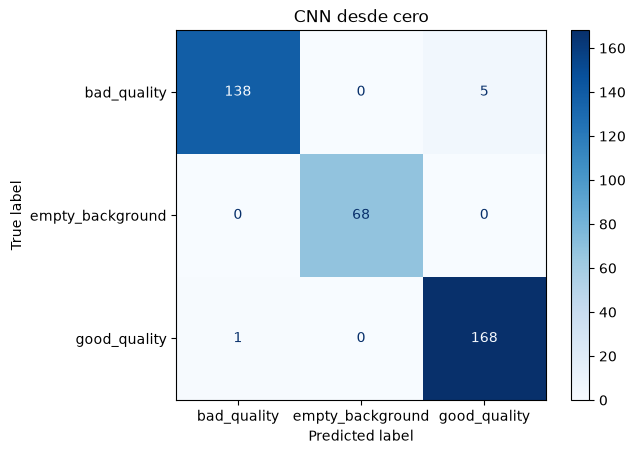


=== ResNet50 (TL + fine-tuning) ===
                  precision    recall  f1-score   support

     bad_quality      1.000     0.986     0.993       143
empty_background      1.000     1.000     1.000        68
    good_quality      0.988     1.000     0.994       169

        accuracy                          0.995       380
       macro avg      0.996     0.995     0.996       380
    weighted avg      0.995     0.995     0.995       380



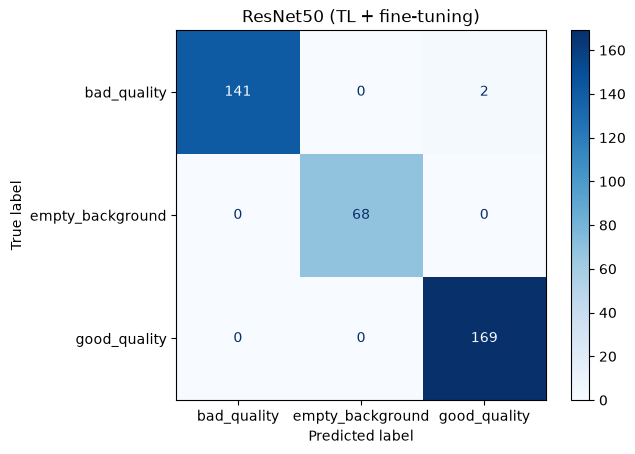

,accuracy,recall bad_quality,F1 macro
CNN desde cero,0.984,0.965,0.987
ResNet50 (TL + fine-tuning),0.995,0.986,0.996


In [7]:
def predict_all(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps += model(x.to(device)).argmax(1).cpu().tolist()
            ys += y.tolist()
    return np.array(ys), np.array(ps)

resultados = {}
for nombre, m in [("CNN desde cero", cnn), ("ResNet50 (TL + fine-tuning)", resnet)]:
    y_true, y_pred = predict_all(m, test_loader)
    print(f"\n=== {nombre} ===")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(cmap="Blues")
    plt.title(nombre); plt.show()
    resultados[nombre] = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

import pandas as pd
tabla = pd.DataFrame({
    n: {"accuracy": r["accuracy"],
        "recall bad_quality": r["bad_quality"]["recall"],
        "F1 macro": r["macro avg"]["f1-score"]}
    for n, r in resultados.items()}).T.round(3)
tabla

## 6. Curva ROC: detección de limón malo
Como el error más costoso es dejar pasar un limón malo, calculamos la curva ROC de `bad_quality` contra el resto. Ambos modelos obtienen AUC = 0.999, así que separan muy bien las clases. La diferencia entre ellos está en el punto de operación (cuántos malos se escapan), no en la capacidad general de discriminar.

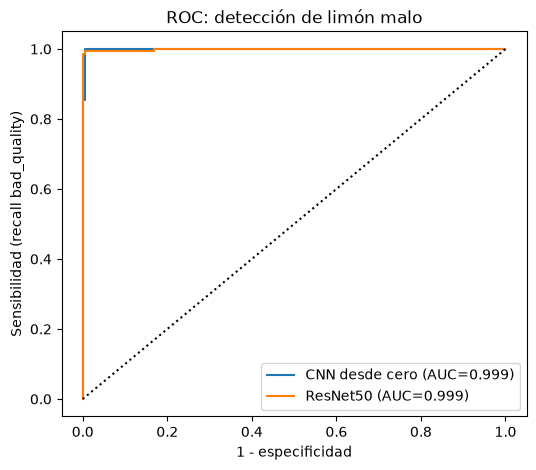

In [8]:
from sklearn.metrics import roc_curve, auc
import torch.nn.functional as F

def probs_all(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps.append(F.softmax(model(x.to(device)), dim=1).cpu().numpy())
            ys += y.tolist()
    return np.array(ys), np.vstack(ps)

plt.figure(figsize=(6, 5))
for nombre, m in [("CNN desde cero", cnn), ("ResNet50", resnet)]:
    y_true, probs = probs_all(m, test_loader)
    idx_bad = class_names.index("bad_quality")
    fpr, tpr, _ = roc_curve(y_true == idx_bad, probs[:, idx_bad])
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k:")
plt.xlabel("1 - especificidad"); plt.ylabel("Sensibilidad (recall bad_quality)")
plt.title("ROC: detección de limón malo"); plt.legend(); plt.show()

## 7. Explicabilidad: Grad-CAM
Para entender qué mira la red usamos Grad-CAM sobre la última capa convolucional. En las imágenes de test, ResNet50 concentra la activación en el cuerpo del limón y en las manchas, y en las imágenes de fondo vacío la activación es difusa. Esto indica que decide con base en el objeto y no en el entorno.

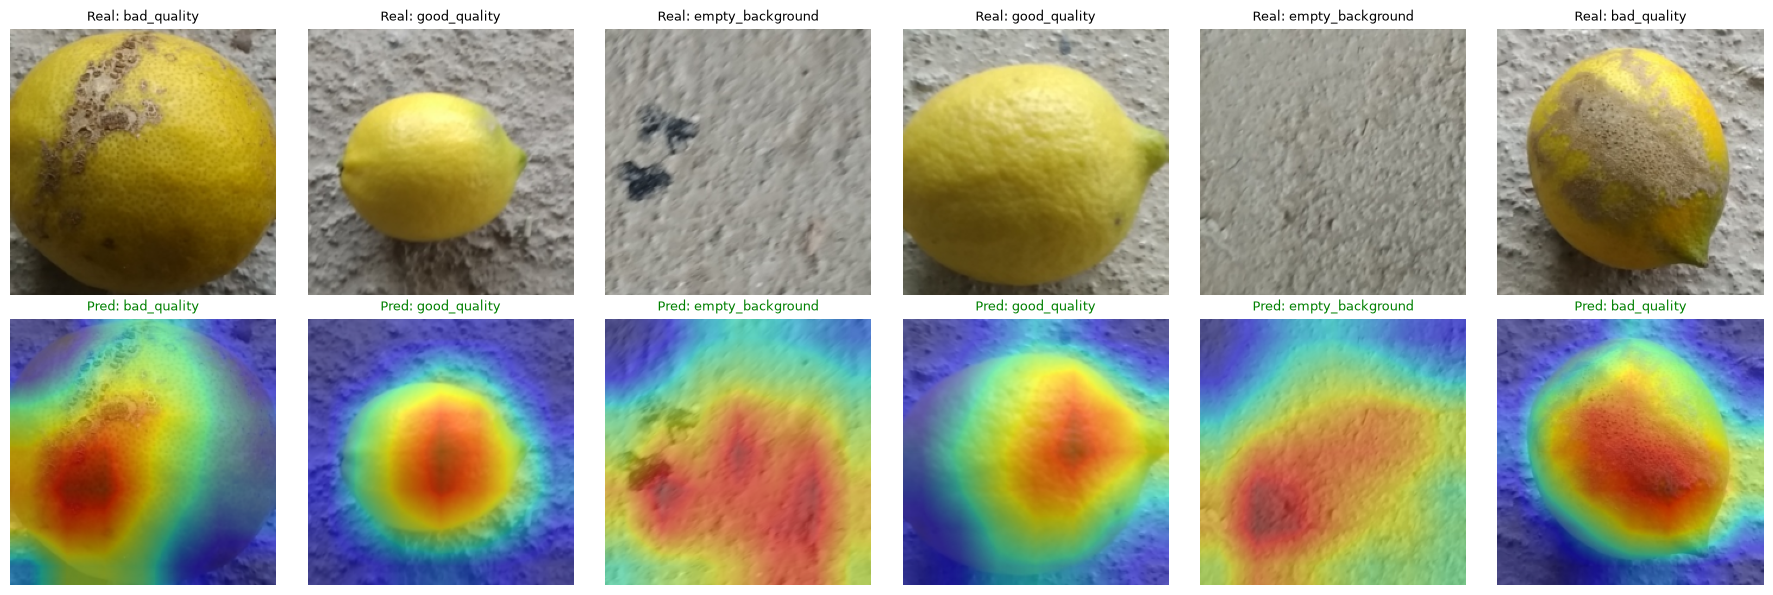

In [9]:
def gradcam(model, img, layer="layer4"):
    model.eval()
    cap = {}
    def fwd(m, i, o):
        cap["act"] = o
        o.register_hook(lambda g: cap.__setitem__("grad", g))
    h = dict(model.named_modules())[layer].register_forward_hook(fwd)

    x = img.unsqueeze(0).to(device).requires_grad_(True)  # necesario porque el cuerpo está congelado
    out = model(x)
    pred = out.argmax(1).item()
    model.zero_grad()
    out[0, pred].backward()
    h.remove()

    cam = compute_gradcam(cap["act"].detach(), cap["grad"].detach())
    cam = resize_cam(cam, x.shape[2], x.shape[3])
    return cam.cpu().numpy(), pred

images, labels = next(iter(test_loader))
fig, axs = plt.subplots(2, 6, figsize=(18, 6))
for k in range(6):
    cam, pred = gradcam(resnet, images[k])
    img = np.clip(images[k].permute(1, 2, 0).numpy() * np.array(std) + np.array(mean), 0, 1)
    heat = plt.get_cmap("jet")(cam)[:, :, :3]
    overlay = np.clip(0.5 * img + 0.5 * heat, 0, 1)
    axs[0, k].imshow(img); axs[0, k].axis("off")
    axs[0, k].set_title(f"Real: {class_names[labels[k]]}", fontsize=9)
    axs[1, k].imshow(overlay); axs[1, k].axis("off")
    axs[1, k].set_title(f"Pred: {class_names[pred]}", fontsize=9,
                        color="green" if pred == labels[k] else "red")
plt.tight_layout(); plt.show()

## 8. Comparación de los modelos
| Modelo | Accuracy | Recall `bad_quality` | F1 macro | Parámetros | ms por imagen |
|---|---|---|---|---|---|
| CNN desde cero | 0.984 | 0.965 | 0.987 | 0.36 M | 12.1 |
| ResNet50 (TL + fine-tuning) | 0.995 | 0.986 | 0.996 | 23.5 M | 47.0 |

ResNet50 es más preciso y deja pasar menos limones malos, pero la CNN es ~65 veces más pequeña y ~4 veces más rápida. La diferencia de accuracy equivale a unas 4 imágenes de 380, así que es real pero modesta.


In [10]:
import time, pandas as pd

def contar_params(m):
    return sum(p.numel() for p in m.parameters())

def ms_por_imagen(m, loader, repeticiones=5):
    m.eval()
    x, _ = next(iter(loader))
    x = x.to(device)
    with torch.no_grad():
        m(x)  # calentamiento
        if device.type == "cuda": torch.cuda.synchronize()
        t = time.time()
        for _ in range(repeticiones):
            m(x)
        if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / (repeticiones * len(x)) * 1000

filas = {}
for nombre, m in [("CNN desde cero", cnn), ("ResNet50 (TL + fine-tuning)", resnet)]:
    r = resultados[nombre]
    filas[nombre] = {
        "accuracy": r["accuracy"],
        "recall bad_quality": r["bad_quality"]["recall"],
        "F1 macro": r["macro avg"]["f1-score"],
        "parámetros (M)": contar_params(m) / 1e6,
        "ms por imagen": ms_por_imagen(m, test_loader),
    }
tabla = pd.DataFrame(filas).T.round(3)
tabla

,accuracy,recall bad_quality,F1 macro,parámetros (M),ms por imagen
CNN desde cero,0.984,0.965,0.987,0.356,12.104
ResNet50 (TL + fine-tuning),0.995,0.986,0.996,23.514,46.961


## 9. Análisis de errores
Revisamos las imágenes mal clasificadas con su Grad-CAM.
- **ResNet50 (2 errores):** ambos son `bad_quality` clasificados como `good_quality`. Son defectos muy sutiles (una marca tenue y una pequeña cicatriz). En el mapa de calor el modelo mira una esquina del fondo y no el defecto.
- **CNN propia (6 errores):** 5 malos clasificados como buenos (manchas leves o pequeñas) y 1 bueno clasificado como malo.
- Conclusión: los errores se concentran en defectos leves, que son justo el caso ambiguo también para una persona.

ResNet50: 2 errores en test


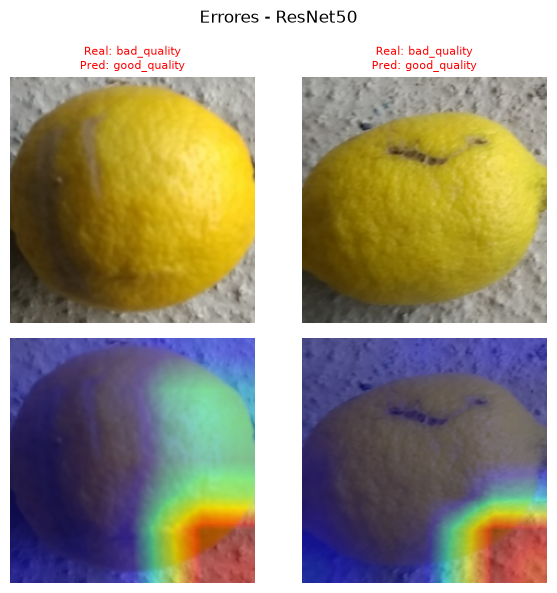

CNN desde cero: 6 errores en test


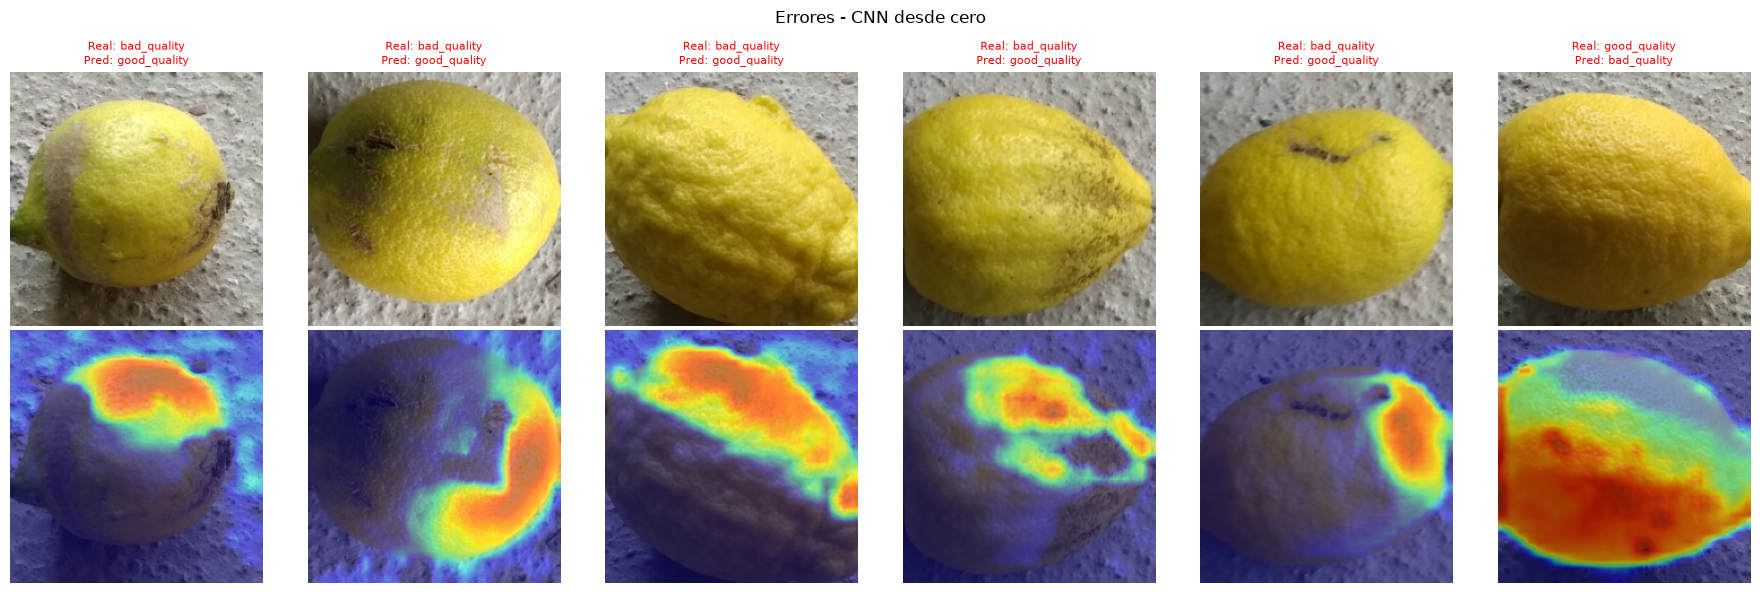

In [11]:
def mostrar_errores(model, nombre, layer, max_img=6):
    model.eval()
    errores = []  # (imagen, real, pred)
    for x, y in test_loader:
        with torch.no_grad():
            pred = model(x.to(device)).argmax(1).cpu()
        for i in range(len(y)):
            if pred[i] != y[i]:
                errores.append((x[i], y[i].item(), pred[i].item()))
    print(f"{nombre}: {len(errores)} errores en test")
    if not errores: return

    n = min(max_img, len(errores))
    fig, axs = plt.subplots(2, n, figsize=(3 * n, 6), squeeze=False)
    for k in range(n):
        img_t, real, pred = errores[k]
        cam, _ = gradcam(model, img_t, layer=layer)
        img = np.clip(img_t.permute(1, 2, 0).numpy() * np.array(std) + np.array(mean), 0, 1)
        heat = plt.get_cmap("jet")(cam)[:, :, :3]
        axs[0, k].imshow(img); axs[0, k].axis("off")
        axs[0, k].set_title(f"Real: {class_names[real]}\nPred: {class_names[pred]}", fontsize=8, color="red")
        axs[1, k].imshow(np.clip(0.5 * img + 0.5 * heat, 0, 1)); axs[1, k].axis("off")
    plt.suptitle(f"Errores - {nombre}"); plt.tight_layout(); plt.show()

mostrar_errores(resnet, "ResNet50", layer="layer4")
mostrar_errores(cnn, "CNN desde cero", layer="features.2")

## 10. Prueba con una imagen externa
Probamos una imagen que no pertenece al dataset (otro fondo y otra iluminación). Ambos modelos la clasifican como `bad_quality` con confianza 1.00. Con ResNet50 el mapa de calor se centra en la zona dañada. Con la CNN es más disperso y toca los bordes. Es una sola imagen, así que es un resultado alentador pero **no suficiente para afirmar que el modelo generaliza**.

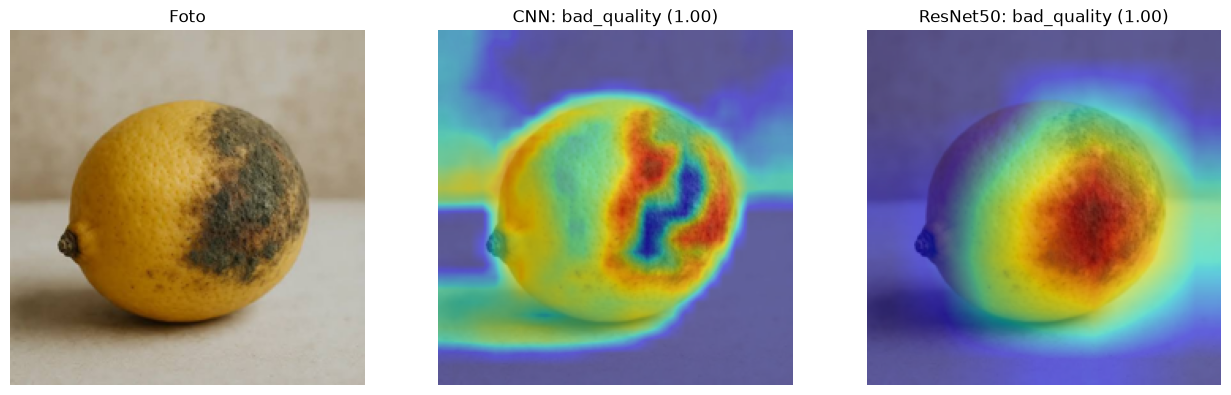

In [12]:
from PIL import Image
from torchvision import transforms

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

def probar_foto(ruta):
    img_pil = Image.open(ruta).convert("RGB")
    x = eval_tf(img_pil)
    fig, axs = plt.subplots(1, 3, figsize=(13, 4))
    axs[0].imshow(img_pil.resize((224, 224))); axs[0].set_title("Foto"); axs[0].axis("off")
    for ax, (nombre, m, layer) in zip(axs[1:], [("CNN", cnn, "features.2"), ("ResNet50", resnet, "layer4")]):
        cam, pred = gradcam(m, x, layer=layer)
        with torch.no_grad():
            probs = torch.softmax(m(x.unsqueeze(0).to(device)), 1)[0].cpu()
        img = np.clip(x.permute(1, 2, 0).numpy() * np.array(std) + np.array(mean), 0, 1)
        heat = plt.get_cmap("jet")(cam)[:, :, :3]
        ax.imshow(np.clip(0.5 * img + 0.5 * heat, 0, 1)); ax.axis("off")
        ax.set_title(f"{nombre}: {class_names[pred]} ({probs[pred]:.2f})")
    plt.tight_layout(); plt.show()

probar_foto("archive/fotos_propias/limon1.jpeg")   # ajusta al nombre que salga

## 11. Conclusiones
- Ambos modelos superan el 98% de accuracy. ResNet50 es mejor (99.5%) y deja pasar menos limones malos, mientras que la CNN propia es mucho más liviana y rápida.
- Los errores se concentran en defectos sutiles y, en ResNet50, el Grad-CAM sugiere que a veces mira el fondo.
- **Limitaciones:** el dataset es muy homogéneo (mismo fondo y luz), el test es pequeño, no verificamos si hay fotos del mismo limón repartidas entre train y test, y la prueba externa fue de una sola imagen.
- **Ético/práctico:** el falso negativo (despachar un limón malo) es el error más costoso. Proponemos un umbral de confianza con revisión humana cuando el modelo dude, y reentrenar con fotos de la línea real antes de desplegarlo. El sistema debe asistir al inspector, no reemplazarlo.